In [5]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from  util.dynamics import evolve_feedback

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns

# from util import evolve

In [2]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0)

df_TEs.head()

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Min.,Threshold (°C) – Est.,Threshold (°C) – Max.,Beta (1/°C),Max Impact (°C) – Global,Comments
TE,,,,,,,,,
AMAZ,Amazon rainforest dieback,100,1000,2.0,3.5,6.0,4.604503,0.20,"Max impact for a total die back is 0.2C, while..."
AMOC,Atlantic meridional ocean circulation,50,500,1.4,4.0,8.0,2.656444,-0.50,NaN
ASI,Arctic winter sea ice,20,200,4.5,6.3,8.7,3.837086,0.60,NaN
ENSO,El Nino Southern Oscillation,100,1000,3.0,4.5,6.0,4.604503,0.00,From Armstrong McKay et al no estimate for max...
GIS,Greenland ice sheet,10000,100000,0.8,1.5,3.0,9.866793,0.13,NaN


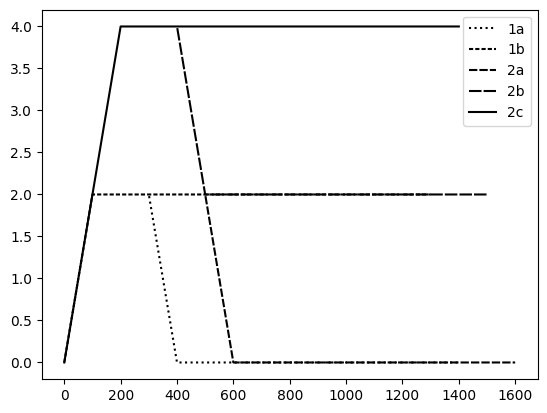

In [3]:
# Scenarios:
    # 1) Ramp up to 2C, stabilise for 200y @ 2C
        # 1a) Ramp down to 0, stabilise for another 1ky
        # 1b) Remain at 2C, stabilise for another 1ky
    # 2) Ramp up to 4C, stabilise for 200y @ 4C
        # 2a) Ramp down to 0, stabilise for another 1ky
        # 2b) Ramp down to 2C, stabilise for another 1ky
        # 2c) Remain at 4C, stabilise for another 1ky
scenarios = ['1a','1b','2a','2b','2c']
temps = {}
temps['1a'] = np.concatenate((np.arange(0,2.01,step=0.02),
                              np.ones(200)*2,
                              np.arange(0,2,step=0.02)[::-1], 
                              np.zeros(1000)) 
                            )
temps['1b'] = np.concatenate((np.arange(0,2.01,step=0.02),
                         np.ones(1200)*2))
# temps['1c'] = np.concatenate((np.arange(0,2.01,step=0.02),
#                          np.ones(1200)*2,
#                          np.arange(0,2,step=0.02)[::-1]))

temps['2a'] = np.concatenate((np.arange(0,4.01,step=0.02),
                              np.ones(200)*4,
                              np.arange(0,4,step=0.02)[::-1],
                              np.zeros(1000)))
temps['2b'] = np.concatenate((np.arange(0,4.01,step=0.02),
                              np.ones(200)*4,
                              np.arange(2,4,step=0.02)[::-1],
                              np.ones(1000)*2))
temps['2c'] = np.concatenate((np.arange(0,4.01,step=0.02),
                         np.ones(1200)*4))

linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
start_points = {'1a':len(np.concatenate((np.arange(0,2.01,step=0.02),
                                         np.ones(200)*2))),
                '1b':0,
                '2a':len(np.concatenate((np.arange(0,4.01,step=0.02),
                                         np.ones(200)*2,
                                         np.arange(2,4,step=0.02)[::-1]))), 
                '2b':len(np.concatenate((np.arange(0,4.01,step=0.02),
                                         np.ones(200)*2))),
                '2c':0}
for i,s in enumerate(scenarios):
    # if s=='2b':
    #     continue
    plt.plot(range(start_points[s],len(temps[s])),
             temps[s][start_points[s]:],label=s,color='k',ls=linestyles[i])
plt.legend()

In [4]:
folder = "../../Data/Interaction matrices/"
no_samples = 500
A = [np.loadtxt(folder+'A_'+str(r)+'.csv') for r in range(no_samples)]

In [ ]:
help(util.dynamics.environmental_update)

In [ ]:
pc['1a'].shape

In [5]:
# D = {s: np.array([util.evolve(np.zeros(9), A[r], len(temps[s]),
#                  tau_c = df_TEs['Collapse (years)'].to_numpy(),
#                  tau_r = df_TEs['Recovery (years)'].to_numpy(),
#                  T = temps[s],
#                  beta=df_TEs['Beta (1/°C)'].to_numpy(),
#                  T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy()) for r in tqdm.tqdm(range(no_samples))]) 
#      for s in scenarios}
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy()
beta = df_TEs['Beta (1/°C)'].to_numpy()
# pc = {s:np.ones((len(temps[s]), len(df_TEs))) for s in scenarios}
pr = 1/(1+df_TEs['Recovery (years)'].to_numpy())
# for s in scenarios:
#     pc[s] /= 1+df_TEs['Collapse (years)'].to_numpy()
#     for t,T in enumerate(temps[s]):
#         pc[s][t] *= util.dynamics.temp_response(T, T_lim, beta)
# D = {s: np.array([[util.dynamics.environmental_update(np.zeros(9), A[r], pc[s][t,:], pr) 
#                    for t in range(len(temps[s]))] 
#                   for r in (range(no_samples))]) 
#      for s in scenarios}
D = {s: np.zeros( (500, len(temps[s]), 9) ) for s in scenarios}
for s in scenarios:
    for r in range (500):
        for t in range(1,len(temps[s])):
            pc = util.dynamics.temp_response(temps[s][t],T_lim,beta)/(1+df_TEs['Collapse (years)'].to_numpy())
            D[s][r,t,:] = util.dynamics.environmental_update(D[s][r,t-1,:], A[r], pc, pr)

In [ ]:
temps['1a']

In [ ]:
pc['1a'].shape

In [6]:
start_points = {'1a':len(np.concatenate((np.arange(0,2.01,step=0.02),
                                         np.ones(200)*2))),
                '1b':0,
                '2a':len(np.concatenate((np.arange(0,4.01,step=0.02),
                                         np.ones(200)*2,
                                         np.arange(2,4,step=0.02)[::-1]))), 
                '2b':len(np.concatenate((np.arange(0,4.01,step=0.02),
                                         np.ones(200)*2))),
                '2c':0}

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

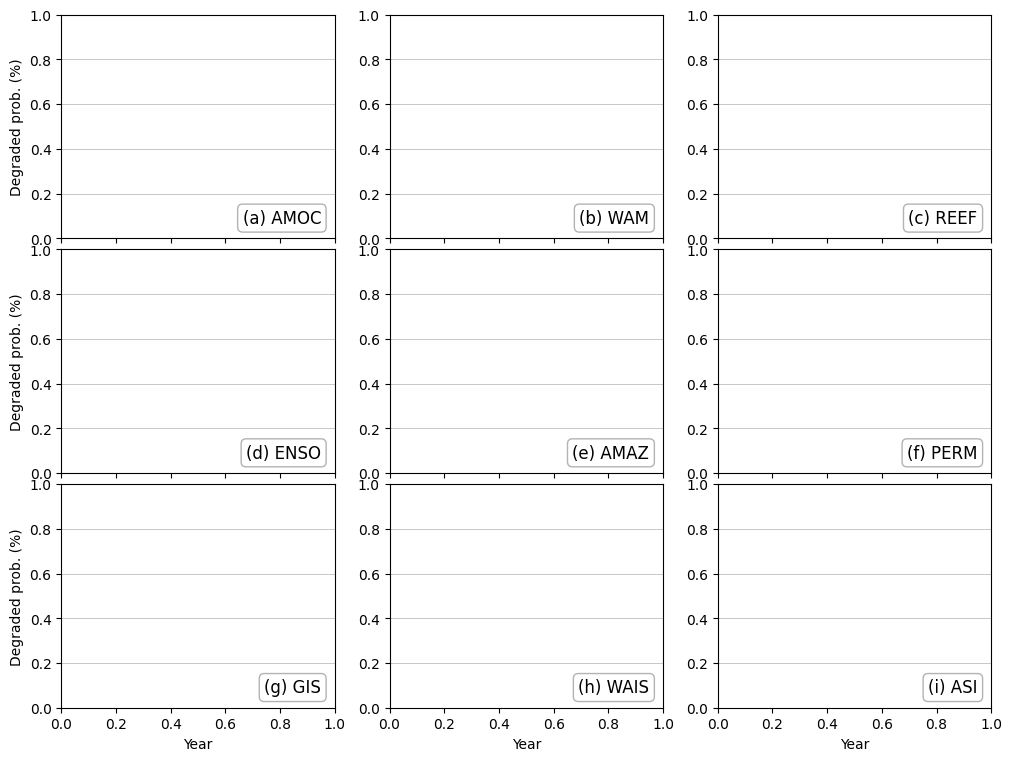

In [8]:
fig,axs  = util.plot.TE_3x3_fig()
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
TE_ind = {te:i for i,te in enumerate(TEs)}

for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    for j,s in enumerate(scenarios):
        axs[i_ax//3,i_ax%3].plot(pc[s][:,i])

In [18]:
D1 = {s: np.array([util.dynamics.evolve(np.zeros(9), A[r], len(temps[s]),
                                        tau_c = df_TEs['Collapse (years)'].to_numpy(),
                                        tau_r = df_TEs['Recovery (years)'].to_numpy(),
                                        T = temps[s],
                                        beta=df_TEs['Beta (1/°C)'].to_numpy(),
                                        T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy(),
                                        order_ST=False) 
                   for r in (range(no_samples))]) 
     for s in scenarios}

In [21]:
np.mean(np.abs(D['1a'] - D1['1a'].transpose((0,2,1))))

np.float64(1.22551324293547e-19)

## plotting

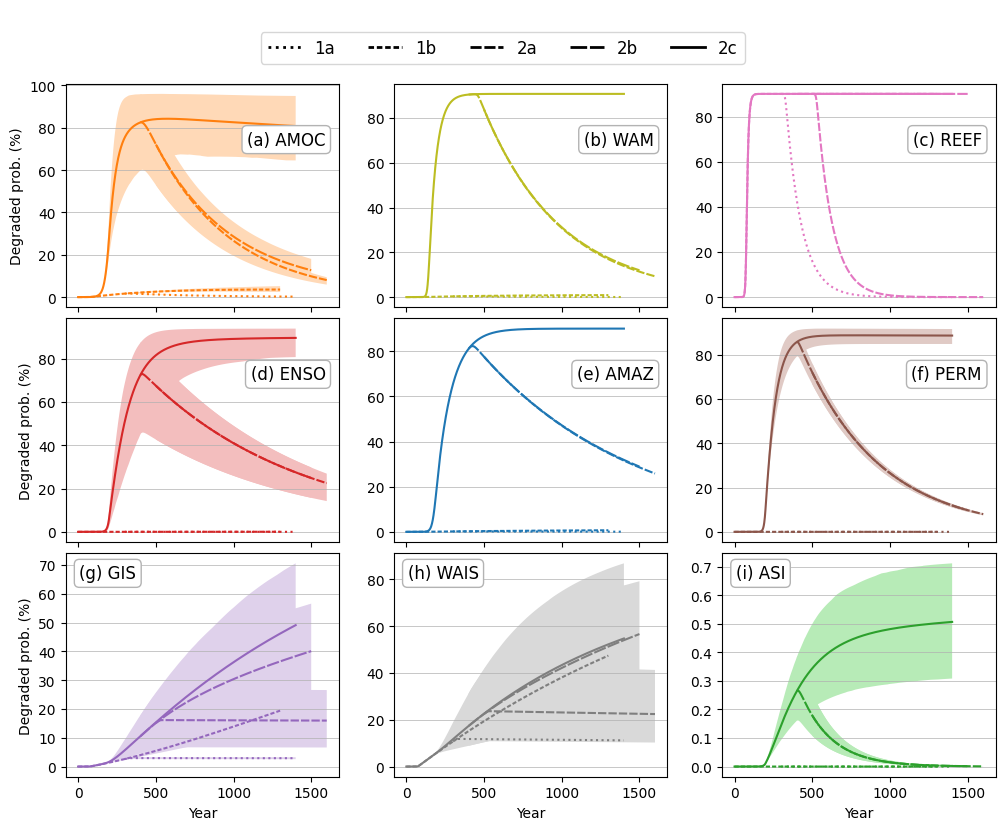

In [12]:
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
TE_ind = {te:i for i,te in enumerate(TEs)}

# locs = [(0.95,0.5),(0.95,0.5),(0.95,0.5), ]
locs = [(0.95,0.75)]*6 + [(0.05,0.95)]*3
has = ['right']*6 + ['left']*3
vas= ['center']*6 + ['top']*3
fig,axs = util.plot.TE_3x3_fig(TE_ordered=TE_ordered, subfig_lab_loc=locs,ha=has,va=vas,fontsize=12)
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
# linestyles = linestyles[::-1]

for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    for j,s in enumerate(scenarios):
        util.plot.ribbon_plot(axs[i_ax//3,i_ax%3], 
                         range(start_points[s],len(temps[s])), 
                         D[s][:,start_points[s]:,i]*100, 
                         color=util.plot.lighten_color(colors[i],1),axis=0,
                         alpha=[1],shade=[0.3])
        axs[i_ax//3,i_ax%3].plot(range(start_points[s],len(temps[s])),
                                 D[s][:,start_points[s]:,i].mean(axis=0)*100,
                                 c=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)

lines = [Line2D([0], [0], color=util.plot.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scenarios[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]
fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)

TypeError: list indices must be integers or slices, not tuple

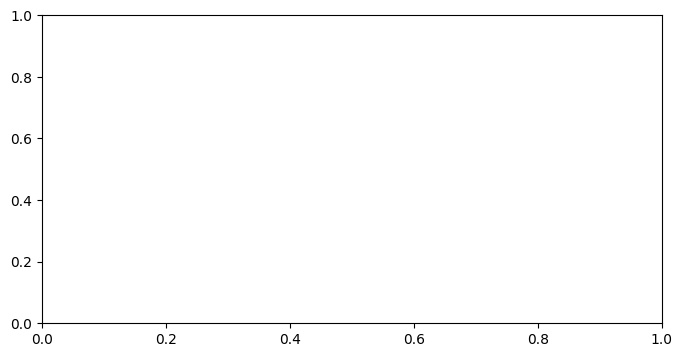

In [18]:
fig,ax = plt.subplots(figsize=(8,4))
labels = [r'2$\rightarrow$0', '2', r'4$\rightarrow$0', r'4$\rightarrow$2', '4']
for j,s in enumerate(scenarios[::-1]):
    util.plot.ribbon_plot(ax,
                          range(start_points[s],len(temps[s])), 
                          D[s][:,start_points[s]:,:].sum(axis=2), 
                          color='seagreen',axis=0,
                          alpha=[1]*2,quantiles=[0.05,0.25],shade=[0.3,0.65],label=['']*2)
    ax.plot(range(start_points[s],len(temps[s])),
            D[s][:,start_points[s]:,:].sum(axis=2).mean(axis=0),
            color=util.plot.lighten_color('seagreen',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])

ax.grid()
# ax.set_xlim([1850,2350])
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Time (years)')

# ax_temp = ax.inset_axes([1850, 1, 170, 3.5], transform=ax.transData)
# ax_temp.yaxis.tick_right()
# ax_temp.set_xlim([1850,2350])
# ax_temp.set_xticks([1900,2100,2300])
# ax_temp.tick_params(axis='both', which='major', labelsize=8)
# for j,s in enumerate(scenarios):
#     # ax_temp.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
#     ax_temp.plot(years,dfs[s]['mean'].to_numpy(), color=colors[j])

legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

In [19]:
D['1a'].shape

AttributeError: 'list' object has no attribute 'shape'

# including warming feedbacks

In [2]:
def evolve_feedback(D_init, A, no_time_steps, 
           order_ST=False, 
           pc = None, tau_c = None, 
           T = None, beta = None, T_lim = None,
           pr = None, tau_r = None, impact = None
           ):
    """ 
    Wrapper to evolve system up to and including t = no_time_steps, 
    with an initial value of D_init at time t=0, taking into account the warming feedbacks due to tipping impacts.

    Parameters (required)
    ---
    D_init : numpy.array
        The initial array of degraded probabilities at time step 0
    A : numpy.array
        The interaction matrix (i.e. adjacency matrix), must be of shape (len(D_init), len(D_init)). 
        No self loops, i.e. all diagonal elements should be 0. 
    no_time_steps : int
        The number of time steps to simulate over, 
        i.e. the number of times the update equation is successively applied. 
        Must be >= 1
    
    Parameters (optional):
    order_ST : Bool
        The indexing order of the adjacent matrix. 
        If True, then the adjacency matrix will be read with an index-order that gives A[source, target].
        Otherwise the order will be assumed as A[target, source]
        Default True.
    pc : numpy.array or something broadcastable
        The array/list/collection of collapse rates (without interactions). 
        Will supercede any calls to tau_c or T
        Must be in [0,1]. 
    tau_c :  numpy.array or something broadcastable
        The array/list/collection of collapse time scales. 
    T : array-like
        The global temperature(s) at which to evaluate. 
        Must be of length >= no_time_steps. Must have beta and T_lim supplied as well if not None
    beta : array-like or float
        Temperature sensitivities (i.e. logistic parameters) for individual tipping points.
        If array-like must be of length len(D_init). 
    T_lim : array-like or float
        Critical temperature thresholds for individual tipping points.
        If array-like must be of length len(D_init)
    pr : numpy.array or something broadcastable
        The array/list/collection of collapse rates. Will supercede tau_r
    tau_r : numpy.array or something broadcastable
        The array/list/collection of collapse time scales
    impact: numpy.array
        The array of maximum (in absolute) warming impacts for each element tipping.
        Must be of length len(D_init)
    
        
    Returns
    ---
    D_out : numpy.array
        The output will be a (len(D_init), no_time_steps+1)-shaped array where the D_out[:,0] = D_init
    Examples
    ---
    """
    ## Initialising D_out
    D_out = np.zeros((len(D_init), no_time_steps))
    D_out[:,0] = D_init
    T_out = np.zeros(len(T))
    T_out[0] = T[0]
    
    ## Changing pc if needed
    if pc is None:
        if tau_c is None:
            raise ValueError("No collapse time scales given")
            pc = np.ones(len(D_init))/2 ## if nothing is supplied pc will be set to 1/2
        else:
            # if any of T,T_lim,beta are None, then pc = 1/(tau_c+1)
            pc = np.ones((len(D_init), no_time_steps))/(tau_c.reshape(len(D_init),1)+1)
        # else:
        #     pc = np.ones((len(D_init), no_time_steps))
        #     pc /= (tau_c.reshape(len(D_init),1)+1)
        #     for t in range(no_time_steps):
        #         pc[:,t] *= temp_response(T[t], T_lim, beta)
    if np.any(pc>1) or np.any(pc<0):
        raise ValueError("Collapse probability pc not in [0,1]")
    ## Changing pr if needed
    if pr is None:
        if tau_r is None:  
            raise ValueError("No recovery time scales given")
        else:
            pr = 1/(tau_r+1)
    if np.any(pr>1) or np.any(pr<0):
        raise ValueError("Recovery probability pr not in [0,1]")
    if order_ST:
        A = A.transpose()

    for t in range(1,no_time_steps):
        T_out[t] = T[t]+ np.dot(D_out[:,t-1],impact)
        pc[:,t] *= util.dynamics.temp_response(T_out[t], T_lim, beta)
        D_out[:,t] = util.dynamics.environmental_update(D_out[:,t-1],A,pc[:,t],pr)

    return D_out,T_out

## testing

## using evolve_with_feedback

In [6]:
folder = "../../Data/Interaction matrices/"
no_samples = 500
A = [np.loadtxt(folder+'A_'+str(r)+'.csv') for r in range(no_samples)]
outputs = {s: [evolve_feedback(np.zeros(9), A[r], len(temps[s]),
                               tau_c = df_TEs['Collapse (years)'].to_numpy(),
                               tau_r = df_TEs['Recovery (years)'].to_numpy(),
                               T = temps[s],
                               beta=df_TEs['Beta (1/°C)'].to_numpy(),
                               T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy(),
                               impact= df_TEs['Max Impact (°C) – Global'].to_numpy()) 
               for r in tqdm.tqdm(range(no_samples))] 
     for s in scenarios}

 23%|██████████████████▏                                                             | 114/500 [00:04<00:14, 27.01it/s]


KeyboardInterrupt: 

In [ ]:
D_impact = {s:np.array([outputs[s][r][0] for r in range(no_samples)]) for s in scenarios}
T_impact = {s:np.array([outputs[s][r][1] for r in range(no_samples)]) for s in scenarios}

In [68]:
np.std(T_impact['1a'],axis=0)

array([0.00000000e+00, 2.49800181e-16, 2.22044605e-16, ...,
       9.32587341e-15, 3.99680289e-15, 1.19904087e-14], shape=(1401,))

/tmp/ipykernel_6977/3090621115.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


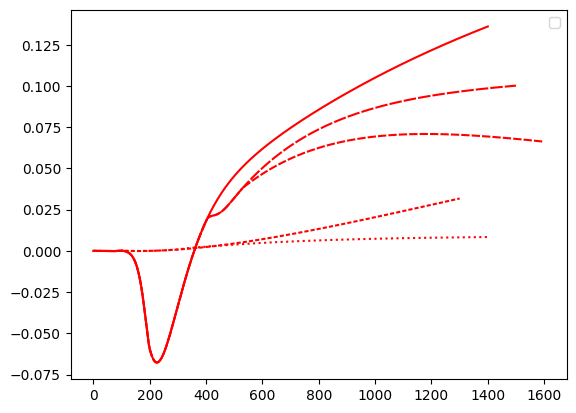

In [75]:
for i,s in enumerate(scenarios):
    # if s=='2b':
    #     continue
    # plt.plot(temps[s],label=s,color='k',ls=linestyles[i])
    plt.plot(T_impact[s].mean(axis=0)-temps[s],color='r',ls=linestyles[i])
plt.legend()

In [40]:
T_impact['1a'].shape

(500, 1401)

In [25]:
T_no_feedback = {s:np.array([np.dot(D[s][:,t,:],df_TEs['Max Impact (°C) – Global'].to_numpy()) 
                             for t in range(len(temps[s]))]) 
                 for s in scenarios}

Text(0.5, 0, 'Time (years)')

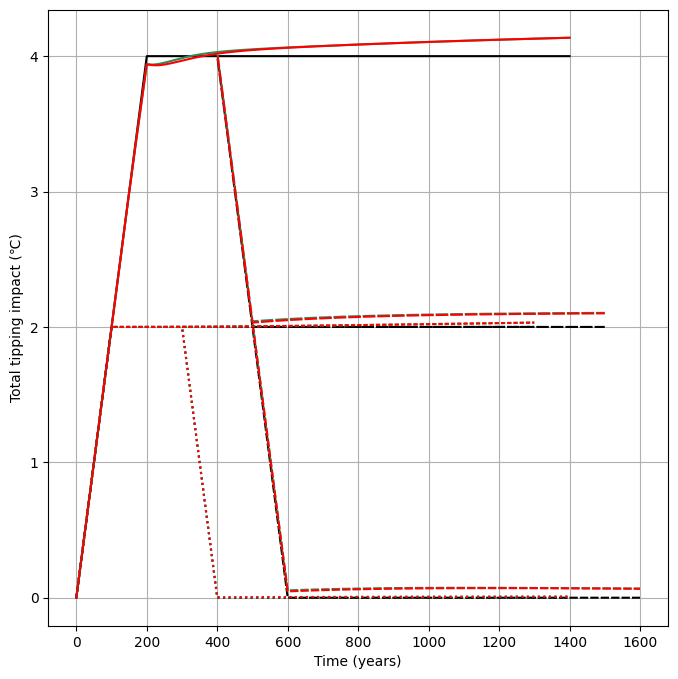

In [91]:
fig,ax = plt.subplots(figsize=(8,8))
labels = [r'2$\rightarrow$0', '2', r'4$\rightarrow$0', r'4$\rightarrow$2', '4']
for j,s in enumerate(scenarios[::-1]):
    # ax.plot(range(start_points[s],len(temps[s])),
    #         T_no_feedback[s][start_points[s]:,:].mean(axis=1),
    #         color=util.plot.lighten_color('seagreen',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])
    # ax.plot(range(start_points[s],len(temps[s])),
    #         T_impact[s][:,start_points[s]:].mean(axis=0)-temps[s][start_points[s]:],
    #         color=util.plot.lighten_color('red',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])
    # ax.plot(range(start_points[s],len(temps[s])),
    #         T_impact[s][:,start_points[s]:].mean(axis=0)-T_no_feedback[s][start_points[s]:,:].mean(axis=1) - temps[s][start_points[s]:],
    #         color=util.plot.lighten_color('k',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])
    ax.plot(range(start_points[s],len(temps[s])),
            temps[s][start_points[s]:],
            color=util.plot.lighten_color('k',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])
    ax.plot(range(start_points[s],len(temps[s])),
            T_no_feedback[s][start_points[s]:,:].mean(axis=1)+temps[s][start_points[s]:],
            color=util.plot.lighten_color('seagreen',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])
    ax.plot(range(start_points[s],len(temps[s])),
            T_impact[s][:,start_points[s]:].mean(axis=0),
            color=util.plot.lighten_color('red',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])

ax.grid()
# ax.set_xlim([1850,2350]
ax.set_ylabel('Total tipping impact (℃)')
ax.set_xlabel('Time (years)')

# legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

In [ ]:
fig,ax = plt.subplots(figsize=(8,4))
labels = [r'2$\rightarrow$0', '2', r'4$\rightarrow$0', r'4$\rightarrow$2', '4']
for j,s in enumerate(scenarios[::-1]):
    ax.plot(range(start_points[s],len(temps[s])),
            T_no_feedback[s][start_points[s]:,:].mean(axis=1)+temps[s][start_points[s]:],
            color=util.lighten_color('r',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])

ax.grid()
ax.set_ylabel('Total tipping impact (℃)')
ax.set_xlabel('Time (years)')

# legend=plt.legend(ncols=1)

In [93]:
D_impact['1a'].shape

(500, 9, 1401)

In [94]:
D['1a'].shape

(500, 1401, 9)

# Comparing with and without feedback

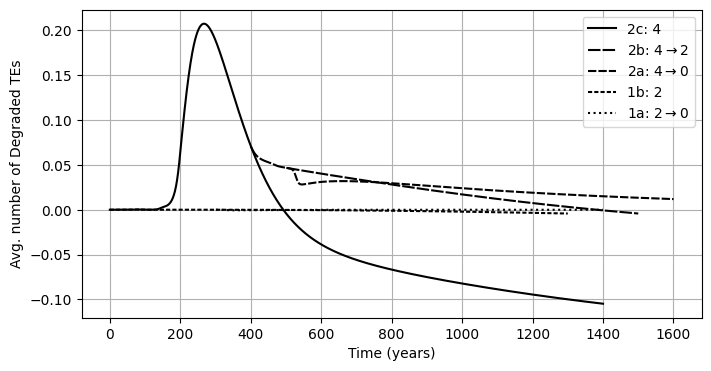

In [98]:
fig,ax = plt.subplots(figsize=(8,4))
labels = [r'2$\rightarrow$0', '2', r'4$\rightarrow$0', r'4$\rightarrow$2', '4']
for j,s in enumerate(scenarios[::-1]):
    # util.plot.ribbon_plot(ax,
    #                       range(start_points[s],len(temps[s])), 
    #                       D[s][:,start_points[s]:,:].sum(axis=2), 
    #                       color='seagreen',axis=0,
    #                       alpha=[1]*2,quantiles=[0.05,0.25],shade=[0.3,0.65],label=['']*2)
    # ax.plot(range(start_points[s],len(temps[s])),
    #         D[s][:,start_points[s]:,:].sum(axis=2).mean(axis=0),
    #         color=util.plot.lighten_color('seagreen',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])
    # ax.plot(range(start_points[s],len(temps[s])),
    #         D_impact[s][:,:,start_points[s]:].sum(axis=1).mean(axis=0),
    #         color=util.plot.lighten_color('red',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])
    ax.plot(range(start_points[s],len(temps[s])),
            D[s][:,start_points[s]:,:].sum(axis=2).mean(axis=0) - D_impact[s][:,:,start_points[s]:].sum(axis=1).mean(axis=0),
            color=util.plot.lighten_color('k',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])

ax.grid()
# ax.set_xlim([1850,2350])
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Time (years)')

# ax_temp = ax.inset_axes([1850, 1, 170, 3.5], transform=ax.transData)
# ax_temp.yaxis.tick_right()
# ax_temp.set_xlim([1850,2350])
# ax_temp.set_xticks([1900,2100,2300])
# ax_temp.tick_params(axis='both', which='major', labelsize=8)
# for j,s in enumerate(scenarios):
#     # ax_temp.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
#     ax_temp.plot(years,dfs[s]['mean'].to_numpy(), color=colors[j])

legend=plt.legend(loc='upper right',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

# Four-fold experiments under overshoots scenarios
## interactions x feedback

In [7]:
from util.dynamics import evolve_feedback
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)

In [8]:
D = {}
folder = "../../Data/Interaction matrices/"
no_samples = 500
A = [np.loadtxt(folder+'A_'+str(r)+'.csv') for r in range(no_samples)]
for s in tqdm.tqdm(scenarios):
    D_00 = util.dynamics.evolve(np.zeros(9), np.zeros((9,9)), len(temps[s]),
                                tau_c = df_TEs['Collapse (years)'].to_numpy(),
                                tau_r = df_TEs['Recovery (years)'].to_numpy(),
                                T = temps[s],
                                beta=df_TEs['Beta (1/°C)'].to_numpy(),
                                T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy(),
                                order_ST=False)  # no-interactions, no-feedback
    D_I0 = np.array([util.dynamics.evolve(np.zeros(9), A[r], len(temps[s]),
                                          tau_c = df_TEs['Collapse (years)'].to_numpy(),
                                          tau_r = df_TEs['Recovery (years)'].to_numpy(),
                                          T = temps[s],
                                          beta=df_TEs['Beta (1/°C)'].to_numpy(),
                                          T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy(),
                                          order_ST=False) 
                     for r in (range(no_samples))])
    D_0F = evolve_feedback(np.zeros(9), np.zeros((9,9)), len(temps[s]),
                           tau_c = df_TEs['Collapse (years)'].to_numpy(),
                           tau_r = df_TEs['Recovery (years)'].to_numpy(),
                           T = temps[s],
                           beta=df_TEs['Beta (1/°C)'].to_numpy(),
                           T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy(),
                           impact= df_TEs['Max Impact (°C) – Global'].to_numpy())[0]
    D_IF = np.array([evolve_feedback(np.zeros(9), A[r], len(temps[s]),
                                     tau_c = df_TEs['Collapse (years)'].to_numpy(),
                                     tau_r = df_TEs['Recovery (years)'].to_numpy(),
                                     T = temps[s],
                                     beta=df_TEs['Beta (1/°C)'].to_numpy(),
                                     T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy(),
                                     impact= df_TEs['Max Impact (°C) – Global'].to_numpy())[0] 
                     for r in range(no_samples)])
    D[s] = [D_00, D_I0, D_0F, D_IF]

100%|████████████████████████████████████████████████████████████████████████████████████| 5/5 [02:30<00:00, 30.17s/it]


In [9]:
start_points = {'1a':len(np.concatenate((np.arange(0,2.01,step=0.02),
                                         np.ones(200)*2))),
                '1b':0,
                '2a':len(np.concatenate((np.arange(0,4.01,step=0.02),
                                         np.ones(200)*2,
                                         np.arange(2,4,step=0.02)[::-1]))), 
                '2b':len(np.concatenate((np.arange(0,4.01,step=0.02),
                                         np.ones(200)*2))),
                '2c':0}

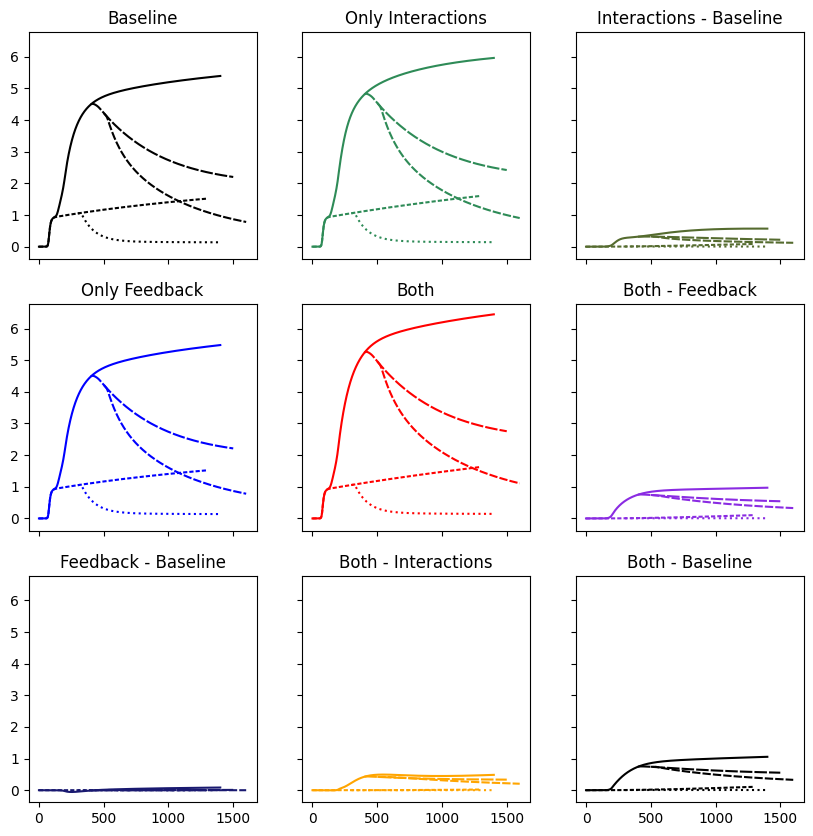

In [12]:
fig,axs = plt.subplots(figsize=(10,10),nrows=3,ncols=3,sharex=True,sharey=True)
# fig.subplots_adjust(hspace=0.05)
for j,s in enumerate(scenarios[::-1]):
    axs[0,0].plot(range(start_points[s],len(temps[s])), 
                  D[s][0][:,start_points[s]:].sum(axis=0), color = 'k',ls=linestyles[::-1][j])
    axs[0,0].set_title('Baseline')
    axs[1,0].plot(range(start_points[s],len(temps[s])), 
                  D[s][2][:,start_points[s]:].sum(axis=0), color = 'b',ls=linestyles[::-1][j])
    axs[1,0].set_title('Only Feedback')
    axs[0,1].plot(range(start_points[s],len(temps[s])), 
                  D[s][1].mean(axis=0)[:,start_points[s]:].sum(axis=0), color = 'seagreen',ls=linestyles[::-1][j])
    axs[0,1].set_title('Only Interactions')
    axs[1,1].plot(range(start_points[s],len(temps[s])), 
                  D[s][3].mean(axis=0)[:,start_points[s]:].sum(axis=0), color = 'red',ls=linestyles[::-1][j])
    axs[1,1].set_title('Both')

    axs[2,0].plot(range(start_points[s],len(temps[s])), 
                  (D[s][2]-D[s][0])[:,start_points[s]:].sum(axis=0), color = 'midnightblue',ls=linestyles[::-1][j])
    axs[2,0].set_title('Feedback - Baseline')
    axs[2,1].plot(range(start_points[s],len(temps[s])), 
                  (D[s][3]-D[s][1]).mean(axis=0)[:,start_points[s]:].sum(axis=0), color = 'orange',ls=linestyles[::-1][j])
    axs[2,1].set_title('Both - Interactions')
    axs[0,2].plot(range(start_points[s],len(temps[s])), 
                  (D[s][1].mean(axis=0)-D[s][0])[:,start_points[s]:].sum(axis=0), color = 'darkolivegreen',ls=linestyles[::-1][j])
    axs[0,2].set_title('Interactions - Baseline')
    axs[1,2].plot(range(start_points[s],len(temps[s])), 
                  (D[s][3].mean(axis=0)-D[s][2])[:,start_points[s]:].sum(axis=0), color = 'blueviolet',ls=linestyles[::-1][j])
    axs[1,2].set_title('Both - Feedback')
    axs[2,2].plot(range(start_points[s],len(temps[s])), 
                  (D[s][3].mean(axis=0) - D[s][0] )[:,start_points[s]:].sum(axis=0), 
                  color = 'k',ls=linestyles[::-1][j])
    axs[2,2].set_title('Both - Baseline')
# for i in range(2):
#     axs[0,i].set_ylim([0,6.5])
#     axs[1,i].set_ylim([0,6.5])

# for i in range(3):
#     axs[i,2].set_ylim([-0.15,0.7])
#     axs[2,i].set_ylim([-0.15,0.7])

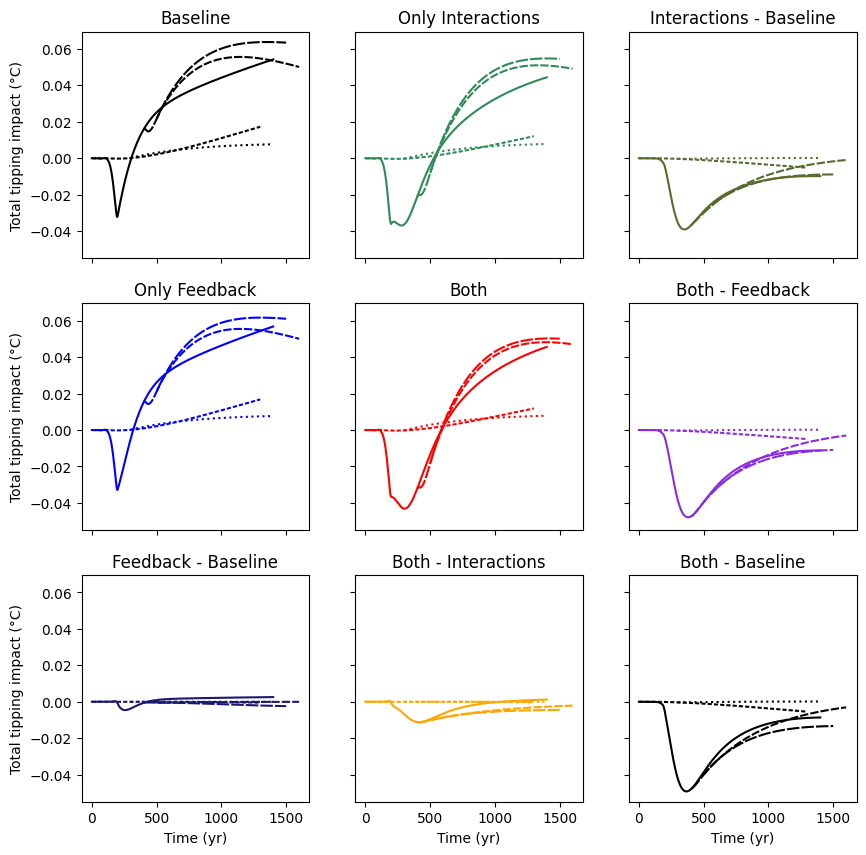

In [21]:
impact = df_TEs['Max Impact (°C) – Global'].to_numpy()
fig,axs = plt.subplots(figsize=(10,10),nrows=3,ncols=3,sharex=True,sharey=True)
# fig.subplots_adjust(hspace=0.05,wspace=0.05)
for j,s in enumerate(scenarios[::-1]):
    axs[0,0].plot(range(start_points[s],len(temps[s])), 
                  np.dot(impact,D[s][0][:,start_points[s]:]), color = 'k',ls=linestyles[::-1][j])
    axs[0,0].set_title('Baseline')
    axs[1,0].plot(range(start_points[s],len(temps[s])), 
                  np.dot(impact,D[s][2][:,start_points[s]:]), color = 'b',ls=linestyles[::-1][j])
    axs[1,0].set_title('Only Feedback')
    axs[0,1].plot(range(start_points[s],len(temps[s])), 
                  np.dot(impact,D[s][1].mean(axis=0)[:,start_points[s]:]), color = 'seagreen',ls=linestyles[::-1][j])
    axs[0,1].set_title('Only Interactions')
    axs[1,1].plot(range(start_points[s],len(temps[s])), 
                  np.dot(impact,D[s][3].mean(axis=0)[:,start_points[s]:]), color = 'red',ls=linestyles[::-1][j])
    axs[1,1].set_title('Both')

    axs[2,0].plot(range(start_points[s],len(temps[s])), 
                  np.dot(impact,(D[s][2]-D[s][0])[:,start_points[s]:]), color = 'midnightblue',ls=linestyles[::-1][j])
    axs[2,0].set_title('Feedback - Baseline')
    axs[2,1].plot(range(start_points[s],len(temps[s])), 
                  np.dot(impact,(D[s][3]-D[s][1]).mean(axis=0)[:,start_points[s]:]), color = 'orange',ls=linestyles[::-1][j])
    axs[2,1].set_title('Both - Interactions')
    axs[0,2].plot(range(start_points[s],len(temps[s])), 
                  np.dot(impact,(D[s][1].mean(axis=0)-D[s][0])[:,start_points[s]:]), color = 'darkolivegreen',ls=linestyles[::-1][j])
    axs[0,2].set_title('Interactions - Baseline')
    axs[1,2].plot(range(start_points[s],len(temps[s])), 
                  np.dot(impact,(D[s][3].mean(axis=0)-D[s][2])[:,start_points[s]:]), color = 'blueviolet',ls=linestyles[::-1][j])
    axs[1,2].set_title('Both - Feedback')
    
    axs[2,2].plot(range(start_points[s],len(temps[s])), 
                  np.dot(impact,(D[s][3].mean(axis=0) - D[s][0] )[:,start_points[s]:]), 
                  color = 'k',ls=linestyles[::-1][j])
    axs[2,2].set_title('Both - Baseline')

for i in range(3):
    axs[2,i].set_xlabel('Time (yr)')
    axs[i,0].set_ylabel('Total tipping impact (°C)')

## Plotting only interactions for overshoots conf.

In [29]:
D['1a'][1].shape

(500, 9, 1401)

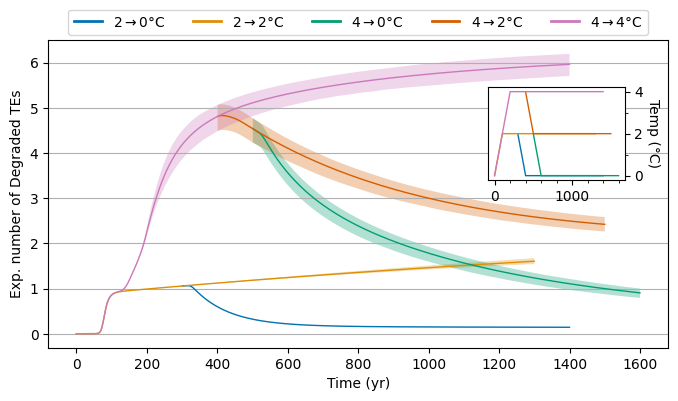

In [67]:
fig,ax = plt.subplots(figsize=(8,4))
colors = sns.color_palette('colorblind',len(scenarios))
for j,s in (enumerate(scenarios)):
    util.plot.ribbon_plot(ax, range(start_points[s],len(temps[s])), 
                          D[s][1].sum(axis=1)[:,start_points[s]:], 
                          quantiles=[0.05],
                          shade = [1,1],alpha=[0.3,0.65], 
                          color=colors[j],label=['']*2)
for j,s in (enumerate(scenarios)):
    ax.plot(range(start_points[s],len(temps[s])),
            D[s][1].sum(axis=1).mean(axis=0)[start_points[s]:],
            color=colors[j],label=scenarios[j],
            lw=1)
    
ax.set_ylabel('Exp. number of Degraded TEs')
ax.set_xlabel('Time (yr)')
ax.grid(axis='y')
# ax.set_xlim([1950,2350])
# ax.yaxis.tick_right()
# ax.yaxis.set_label_position("right")

ax_temp = ax.inset_axes([0.71,0.545,0.22,0.3])
for j,s in enumerate(scenarios):
    ax_temp.plot(range(start_points[s],len(temps[s])),
                 temps[s][start_points[s]:],
            color=colors[j],ls='-',lw=1)
# ax_temp.set_ylabel('Temp (°C)')

ax_temp.yaxis.tick_right()
ax_temp.yaxis.set_label_position("right")
ax_temp.set_ylabel('Temp (°C)',rotation=270,labelpad=12)#,bbox=dict(facecolor='white'),labelpad=15)
ax_temp.yaxis.set_minor_locator(MultipleLocator(1))
ax_temp.xaxis.set_minor_locator(MultipleLocator(200))
# ax_temp.grid(which='both',axis='y')

labels = [r"2$\rightarrow$0°C", r"2$\rightarrow$2°C", 
          r"4$\rightarrow$0°C", r"4$\rightarrow$2°C", r"4$\rightarrow$4°C"]
lines = [Line2D([0], [0], color=colors[j],#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=labels[j], 
                ls = '-')
         for j in range(len(scenarios))]
ax.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':10},bbox_to_anchor=(0.5,1.12))

# legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig('../../Figures/Overshoots/ES_tipmip_scenarios.png',format='png',dpi=300,bbox_inches='tight')

Text(0.5, 1.0, '2°C$\\rightarrow$4°C')

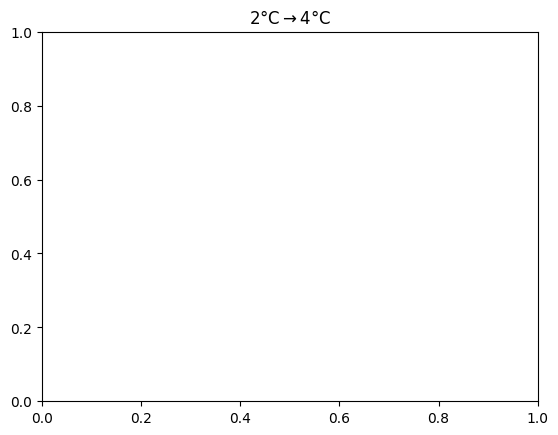

In [62]:
plt.figure()
plt.title(r"2°C$\rightarrow$4°C")

# Plotting ssps with overshoots for conference

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(1, '../')
import util
import seaborn as sns
from matplotlib.lines import Line2D
import pandas as pd
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)

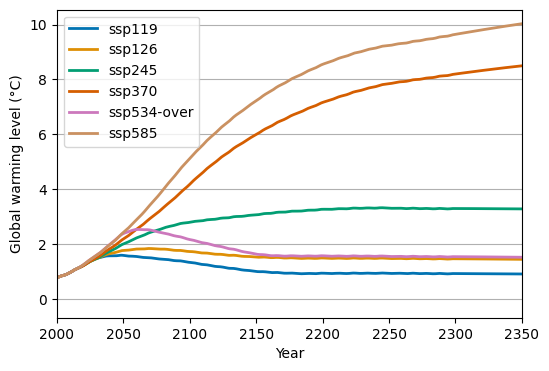

In [15]:
df = pd.read_excel('../../Data/extendedSSPs.xlsx')
scenarios = df['scenario'].unique()
dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}

fig,ax = plt.subplots(figsize=(6,4))
colors = sns.color_palette('colorblind',len(scenarios))
years=np.arange(1850,2351)

for j,s in enumerate(scenarios):
    ax.plot(years,dfs[s]['mean'].to_numpy(),
            color=colors[j],label=scenarios[j],ls='-',lw=2)
ax.legend(loc='upper left')
ax.grid(axis='y')
ax.set_xlim([2000,2350])
ax.set_ylabel('Global warming level (°C)')
ax.set_xlabel('Year')

folder_out = '../../Figures/Overshoots/'
# fig.savefig(folder_out+'GWL_ssps_with_534.png',format='png',dpi=300,bbox_inches='tight')

In [16]:
folder= "../../Data/Simulations/Extended SSPs/"
scenarios = ['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp534-over', 'ssp585'] # the manuscript doesn't contain ssp534-over
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']
# scenarios = ['ssp119', 'ssp126','ssp534-over']
D = np.array([[np.loadtxt(folder+"D_"+te+"_"+scenarios[j]+".csv") 
                     for i,te in enumerate(TEs)] for j in range(len(scenarios))]).transpose((0,2,1,3))
D_noint = np.array([[np.loadtxt(folder+"D_no_interaction_"+te+"_"+scenarios[j]+".csv") 
                     for i,te in enumerate(TEs)] for j in range(len(scenarios))])

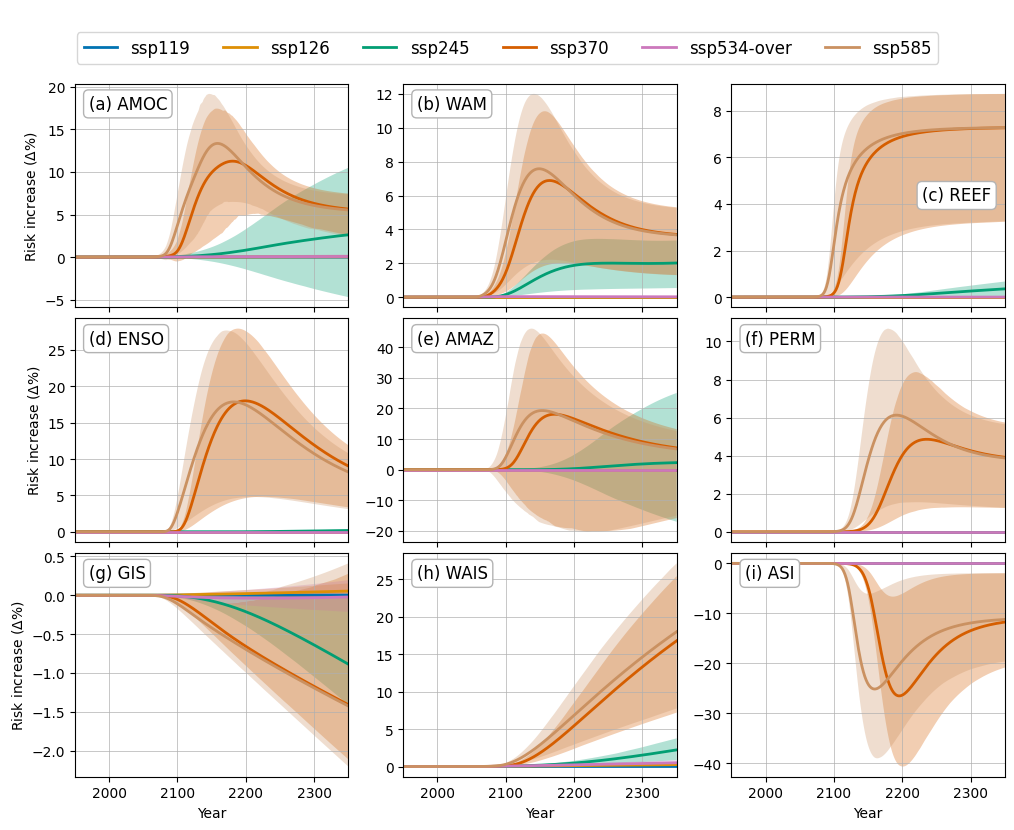

In [138]:
years = np.arange(1850, 2351) 

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
locs = [(0.05,0.95)]*9
locs[2] = (0.95,0.5)
has = ['left']*9
has[2] = 'right'
vas= ['top']*9
vas[2] = 'center'
fig,axs = util.plot.TE_3x3_fig(TE_ordered=TE_ordered, subfig_lab_loc=locs,ha=has,va=vas,fontsize=12)
colors = sns.color_palette('colorblind',len(scenarios))

for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(scenarios)):
        util.plot.ribbon_plot(axs[i_ax//3,i_ax%3], years, (D[j,:,i,:]-D_noint[j,i,:])*100, shade = [1],alpha=[0.3], color=colors[j])
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,(D[j,:,i,:]-D_noint[j,i,:]).mean(axis=0)*100,
                                 c=colors[j],
                                 lw=2)
    axs[i_ax//3,i_ax%3].set_xlim([1950,2350])

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines = [Line2D([0], [0], color=colors[j],#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scenarios[j], 
                ls = '-')
         for j in range(len(scenarios))]

for i in range(3):
    # axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel(r'Risk increase ($\Delta \%$)')
    # axs[i,0].set_ylabel(r'Degraded prob. $(\%)$')

fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)

folder_out = '../../Figures/Overshoots/'
fig.savefig(folder_out+'extendedSSPs_inteffect_with_534.png',format='png',dpi=300,bbox_inches='tight')

In [127]:
(D[j,:,:,:]-D_noint[j,:,:]).shape

(500, 9, 501)

## as a whole earth system

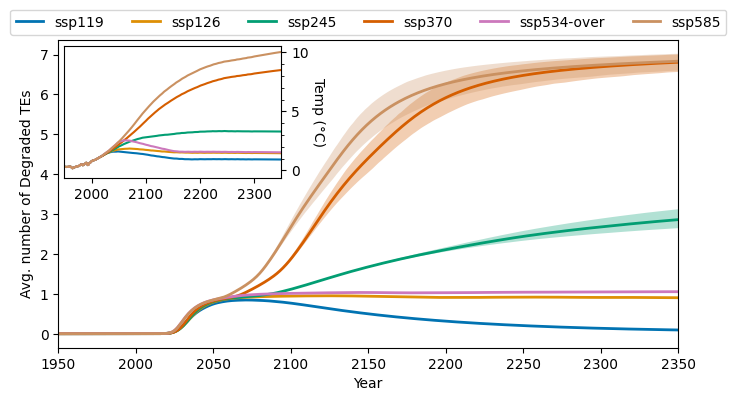

In [20]:
fig,ax = plt.subplots(figsize=(8,4))
colors = sns.color_palette('colorblind',len(scenarios))
years=np.arange(1850,2351)
for j in range(len(scenarios)):
    util.plot.ribbon_plot(ax, years, (D[j,:,:,:]).sum(axis=1), quantiles=[0.05],
                          shade = [1,1],alpha=[0.3,0.65], color=colors[j],label=['']*2)
for j in range(len(scenarios)):
    ax.plot(years,(D[j,:,:,:]).sum(axis=1).mean(axis=0),
        color=colors[j],label=scenarios[j],ls='-',lw=2)
    # ax.plot(years,D_noint[j,:,:].sum(axis=0),
    #                          c=util.lighten_color(colors[j],1), 
    #                          ls='--',lw=1)

# ax.grid(axis='y')
# ax.set_xlim([1850,2350])
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Year')
ax.set_xlim([1950,2350])
# ax.yaxis.tick_right()
# ax.yaxis.set_label_position("right")

ax_temp = ax.inset_axes([0.01,0.55,0.35,0.43])
ax_temp.yaxis.tick_right()
ax_temp.yaxis.set_label_position("right")
for j,s in enumerate(scenarios):
    ax_temp.plot(years,dfs[s]['mean'].to_numpy(),
            color=colors[j],ls='-',lw=1.5)
ax_temp.set_xlim([1950,2350])
ax_temp.set_ylabel('Temp (°C)',rotation=270,labelpad=12)#,bbox=dict(facecolor='white'),labelpad=15)
ax_temp.yaxis.set_minor_locator(MultipleLocator(1))
# ax_temp.grid(which='both',axis='y')

lines = [Line2D([0], [0], color=colors[j],#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scenarios[j], 
                ls = '-')
         for j in range(len(scenarios))]
ax.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':10},bbox_to_anchor=(0.5,1.12))

# ax_temp = ax.inset_axes([1850, 1, 170, 3.5], transform=ax.transData)
# ax_temp.yaxis.tick_right()
# ax_temp.set_xlim([1850,2350])
# ax_temp.set_xticks([1900,2100,2300])
# ax_temp.tick_params(axis='both', which='major', labelsize=8)
# for j,s in enumerate(scenarios):
#     # ax_temp.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
#     ax_temp.plot(years,dfs[s]['mean'].to_numpy(), color=colors[j])

# legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs_with_534.png',format='png',dpi=300,bbox_inches='tight')

In [24]:
print(len(years))
print(2350-1850+1)

501
501


### adding pie charts

([<matplotlib.patches.Wedge at 0x2118415d790>,
 [Text(0.5455160473588948, 0.24982442249293405, 'AMAZ'),
  Text(0.1592704812355509, 0.578474644048463, 'AMOC'),
  Text(-0.3075312202322492, 0.5151937000609226, 'ASI'),
  Text(-0.5831789012539558, 0.14107575671329503, 'ENSO'),
  Text(-0.5877516163959718, -0.12061524540422885, 'GIS'),
  Text(-0.4791860387700545, -0.3610827332452548, 'PERM'),
  Text(-0.024014725112827248, -0.5995192181888378, 'REEF'),
  Text(0.31625805057028483, -0.5098831684312428, 'WAIS'),
  Text(0.5441076151951117, -0.252877249049194, 'WAM')])

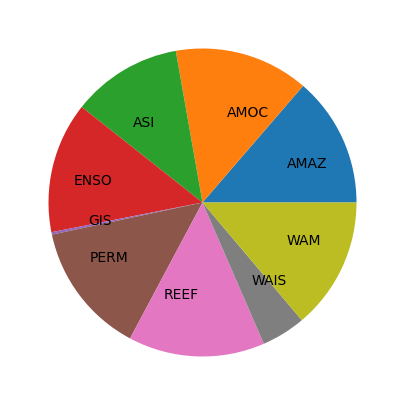

In [30]:
fig,ax=plt.subplots(figsize=(5,5))
scen_to_plot = 'ssp370'
scen_to_ind = {scenarios[j]:j for j in range(len(scenarios))}
year_to_plot = 2350

ax.pie(D[scen_to_ind[scen_to_plot],:,:,year_to_plot-1850].mean(axis=0),labels=TEs,labeldistance=0.6)

In [26]:
TEs

['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']

In [ ]:
(D[j,:,:,:]).sum(axis=1).mean(axis=0)

## Temperature impacts

In [18]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0)
max_impact = df_TEs['Max Impact (°C) – Global'].to_numpy()
impact = np.array([[np.dot(max_impact, D[j,r,:,:]) for r in range(500)] for j in range(len(scenarios))])

In [13]:
impact.shape

(6, 500, 501)

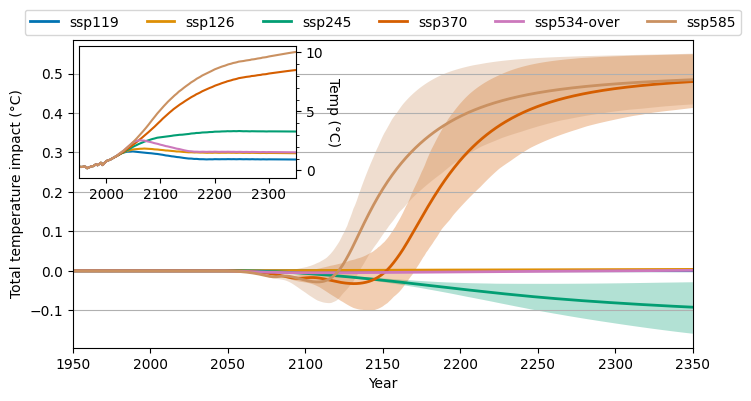

In [19]:
fig,ax = plt.subplots(figsize=(8,4))
colors = sns.color_palette('colorblind',len(scenarios))
years=np.arange(1850,2351)
for j in range(len(scenarios)):
    util.plot.ribbon_plot(ax, years, impact[j,:,:], quantiles=[0.05],
                          shade = [1,1],alpha=[0.3,0.65], color=colors[j],label=['']*2)
for j in range(len(scenarios)):
    ax.plot(years,impact[j,:,:].mean(axis=0),
        color=colors[j],label=scenarios[j],ls='-',lw=2)
    # ax.plot(years,dfs[scenarios[j]]['mean'].to_numpy(),
    #     color=colors[j],label=scenarios[j],ls='-',lw=2)
    # ax.plot(years,D_noint[j,:,:].sum(axis=0),
    #                          c=util.lighten_color(colors[j],1), 
    #                          ls='--',lw=1)

ax.grid(axis='y')
# ax.set_xlim([1850,2350])
ax.set_ylabel('Total temperature impact (°C)')
ax.set_xlabel('Year')
ax.set_xlim([1950,2350])

ax_temp = ax.inset_axes([0.01,0.55,0.35,0.43])
ax_temp.yaxis.tick_right()
ax_temp.yaxis.set_label_position("right")
for j,s in enumerate(scenarios):
    ax_temp.plot(years,dfs[s]['mean'].to_numpy(),
            color=colors[j],ls='-',lw=1.5)
ax_temp.set_xlim([1950,2350])
ax_temp.set_ylabel('Temp (°C)',rotation=270,labelpad=12)#,bbox=dict(facecolor='white'),labelpad=15)
ax_temp.yaxis.set_minor_locator(MultipleLocator(1))
# ax_temp.grid(which='both',axis='y')

lines = [Line2D([0], [0], color=colors[j],#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scenarios[j], 
                ls = '-')
         for j in range(len(scenarios))]
ax.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':10},bbox_to_anchor=(0.5,1.12))

# legend=plt.legend(loc='upper left',ncols=1)
fig.savefig(folder_out+'tipping_impact_with_534_noFeedback.png',format='png',dpi=300,bbox_inches='tight')

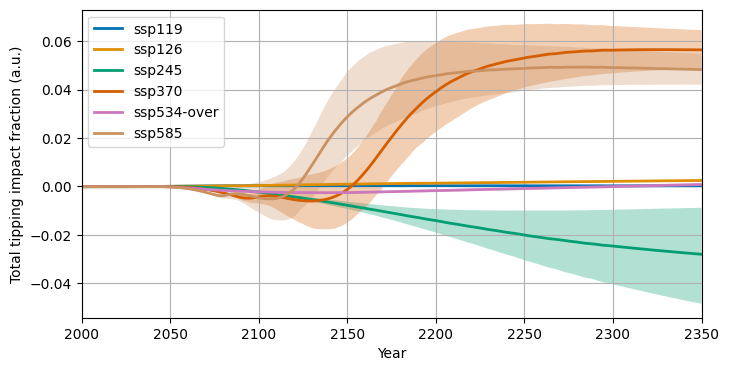

In [37]:
fig,ax = plt.subplots(figsize=(8,4))
colors = sns.color_palette('colorblind',len(scenarios))
years=np.arange(1850,2351)
for j,s in (enumerate(scenarios)):
    util.plot.ribbon_plot(ax, years[150:], impact[j,:,150:]/dfs[s]['mean'].to_numpy()[150:], quantiles=[0.05],
                          shade = [1,1],alpha=[0.3,0.65], color=colors[j],label=['']*2)
for j,s in (enumerate(scenarios)):
    ax.plot(years[150:],impact[j,:,150:].mean(axis=0)/dfs[s]['mean'].to_numpy()[150:],
        color=colors[j],label=scenarios[j],ls='-',lw=2)
    # ax.plot(years,dfs[scenarios[j]]['mean'].to_numpy(),
    #     color=colors[j],label=scenarios[j],ls='-',lw=2)
    # ax.plot(years,D_noint[j,:,:].sum(axis=0),
    #                          c=util.lighten_color(colors[j],1), 
    #                          ls='--',lw=1)

ax.grid()
# ax.set_xlim([1850,2350])
ax.set_ylabel('Total tipping impact fraction (a.u.)')
ax.set_xlabel('Year')
ax.set_xlim([2000,2350])

legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'tipping_impact_with_534_noFeedback.png',format='png',dpi=300,bbox_inches='tight')